# Diffraction and Dispersion: One Equation (Space-Time Duality)

**Colin Casey, 2026.** SymPy for the derivations, NumPy vectorization for the numbers, matplotlib for the figures, and Lean 4 for the exact integer facts. Library: `dgs/diffraction_dispersion.py` (tests: `tests/test_diffraction_dispersion.py`).

## In plain words

A laser beam spreads **sideways** as it travels: that's diffraction. A short light pulse spreads **in time** as it goes down a fiber: that's dispersion. These look like two different topics, but they follow the **same equation**. Replace "position across the beam" with "time within the pulse", and "distance ÷ wavenumber" with "fiber dispersion × length", and every diffraction result becomes a dispersion result.

That one swap is the foundation of the Jalali lab's **photonic time-stretch**:

* **Fraunhofer diffraction** (far from a slit, you see the slit's Fourier transform) becomes the **dispersive Fourier transform**: after enough fiber, a pulse's time trace *is* its spectrum, so a fast oscilloscope works as a spectrometer (the STEAM camera, the time-stretch ADC).
* **Talbot self-imaging** of a grating becomes the **temporal Talbot effect** of a pulse train.
* It is also the **free-particle Schrödinger equation** (Knight Ch. 40): a spreading quantum wave packet is a broadening pulse.

| § | What | Tool |
|---|---|---|
| 1 | The two equations reduce to one; Gaussian solution, widths, far field, Talbot | SymPy |
| 2 | Physical numbers (1550 nm beam, SMF-28 fiber) against closed forms | NumPy |
| 3 | Fig. 1: Gaussian spreading, beam vs pulse on one curve | matplotlib |
| 4 | Fig. 2: far field = Fourier transform (Fraunhofer ↔ time-stretch) | NumPy FFT |
| 5 | Fig. 3: vectorization: Python loop vs broadcasting vs FFT | NumPy |
| 6 | Fig. 4: Talbot carpet, all distances at once by broadcasting | NumPy + matplotlib |
| 7 | Lean 4 proofs of the exact integer facts | Lean |
| 8 | Jalali lab connection and references | |

Kernel: **py312**. Lean: `leanprover/lean4:v4.34.0-rc2`.

In [1]:
import time, pathlib, subprocess
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs import diffraction_dispersion as dd
from dgs.dispersive_fourier import gvd_transfer_function

# Okabe-Ito palette (color-blind safe); curves also differ by line style
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442',
          blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
sp.init_printing()

## 1. The math: two equations, one form (SymPy)

**Diffraction** (paraxial wave equation, field $E(x,z)e^{i(kz-\omega t)}$):
$$\frac{\partial E}{\partial z} = \frac{i}{2k}\frac{\partial^2 E}{\partial x^2}, \qquad H(k_x) = e^{-i k_x^2 z/(2k)}.$$

**Dispersion** (pulse envelope $A(z,T)$ in a fiber, $\beta(\omega)\approx\beta_0+\beta_1\Delta\omega+\tfrac12\beta_2\Delta\omega^2$):
$$\frac{\partial A}{\partial L} = -\frac{i\beta_2}{2}\frac{\partial^2 A}{\partial T^2}, \qquad H(\omega) = e^{i\beta_2 L\omega^2/2}.$$

Both are a **quadratic spectral phase**. Introduce one accumulated quadratic phase $p$ and they become the same equation:
$$\boxed{\frac{\partial u}{\partial p} = -\frac{i}{2}\frac{\partial^2 u}{\partial x^2},\qquad H(\nu)=e^{ip\nu^2/2}}$$

| | variable $x$ | conjugate $\nu$ | quadratic phase $p$ |
|---|---|---|---|
| diffraction | transverse position | $k_x$ | $-z/k$ |
| dispersion | retarded time $T$ | $\omega$ | $\beta_2 L$ (the GDD) |
| Schrödinger (Ch. 40) | position | $k$ | $-\hbar t/m$ |

This matches `dgs.dispersive_fourier.gvd_transfer_function` exactly (checked in §2). A Gaussian $u_0=e^{-x^2/2s_0^2}$ stays Gaussian with a **complex width** $\sigma^2=s_0^2-ip$. SymPy checks that it solves the PDE:

In [2]:
r = dd.sympy_duality()
S = r['symbols']
display(Math(r'u(x,p) = ' + sp.latex(r['u'])))
display(Math(r'\partial_p u + \tfrac{i}{2}\partial_x^2 u = ' + sp.latex(r['residual'])))
display(Math(r'\text{intensity width } s(p) = ' + sp.latex(r['s_of_p'])))
display(Math(r'\text{beam: } w(z) = ' + sp.latex(r['w_beam']) + r',\quad z_R = ' + sp.latex(r['z_R'])))
display(Math(r'\text{pulse: } T(L) = ' + sp.latex(r['T_pulse']) + r',\quad L_D = ' + sp.latex(r['L_D']) + r'\ (\beta_2\to|\beta_2|)'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Far field (stationary phase).** Write $u(x,p)=\frac{1}{2\pi}\int U(\nu)\,e^{i(p\nu^2/2+\nu x)}d\nu$. For large $|p|$ the integral is dominated by the frequency where the phase is stationary:

In [3]:
display(Math(r'\frac{d}{d\nu}\Big(\frac{p\nu^2}{2}+\nu x\Big)=0 \;\Rightarrow\; \nu^* = ' + sp.latex(r['nu_star'])))
display(Math(r'|u(x,p)|^2 \approx \frac{|U(-x/p)|^2}{2\pi|p|}'))
print('Diffraction (p = -z/k):  k_x = k x / z  ->  angle sin(theta) = x/z : Fraunhofer, the far field is the aperture FT.')
print('Dispersion  (p = beta2 L): omega = -T/(beta2 L) : each frequency arrives at its own time -> time-stretch DFT.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Diffraction (p = -z/k):  k_x = k x / z  ->  angle sin(theta) = x/z : Fraunhofer, the far field is the aperture FT.
Dispersion  (p = beta2 L): omega = -T/(beta2 L) : each frequency arrives at its own time -> time-stretch DFT.


**Talbot.** A field with period $\Lambda$ has only the harmonics $\nu_m = 2\pi m/\Lambda$. Each one picks up phase $p\,\nu_m^2/2$:

In [4]:
display(Math(r'\phi_m = ' + sp.latex(r['talbot_phase']) + r'\;=\;2\pi m^2 \text{ when } p_T = ' + sp.latex(r['p_T'])))
display(Math(r'z_T = k\,p_T = ' + sp.latex(r['z_T']) + r',\qquad L_T = \frac{p_T}{|\beta_2|} = \frac{T^2}{\pi|\beta_2|}'))
print('At p_T every harmonic turns a whole number of times (2 pi m^2): the field revives exactly.')
print('At p_T/2 harmonic m turns pi m^2 = pi m (mod 2 pi) since m^2 and m share parity: a copy shifted by half a period (proved in Lean, Sec. 7).')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

At p_T every harmonic turns a whole number of times (2 pi m^2): the field revives exactly.
At p_T/2 harmonic m turns pi m^2 = pi m (mod 2 pi) since m^2 and m share parity: a copy shifted by half a period (proved in Lean, Sec. 7).


## 2. Numbers against closed forms

Physical examples: a 1550 nm beam with a 1 mm waist, and a 1 ps pulse in SMF-28 ($\beta_2\approx-21.7\ \mathrm{ps^2/km}$). In the $e^{-x^2/w_0^2}$ convention $s_0=w_0/\sqrt2$, so $z_R=k s_0^2=\pi w_0^2/\lambda$.

In [5]:
lam, w0 = 1550e-9, 1e-3
k = 2*np.pi/lam
s0_beam = w0/np.sqrt(2)
zR = k*s0_beam**2
beta2 = -21.7e-27            # s^2/m  (-21.7 ps^2/km)
T0 = 1e-12
LD = T0**2/abs(beta2)
Lam, Tper = 100e-6, 100e-12   # 100 um grating, 10 GHz pulse train
rows = [
    ('Rayleigh range z_R = pi w0^2/lambda', zR, np.pi*w0**2/lam, 'm'),
    ('Dispersion length L_D = T0^2/|beta2|', LD, 1/21.7*1e3, 'm'),
    ('Spatial Talbot z_T = 2 Lambda^2/lambda', dd.talbot_length_diffraction(Lam, lam), 2*Lam**2/lam, 'm'),
    ('Temporal Talbot L_T = T^2/(pi|beta2|)', dd.talbot_length_dispersion(Tper, beta2), (100**2/(np.pi*21.7))*1e3, 'm'),
]
print(f"{'quantity':42s} {'module':>12s} {'closed form':>12s}")
for name, a, b, unit in rows:
    print(f'{name:42s} {a:12.4g} {b:12.4g} {unit}')
    assert np.isclose(a, b)

# same transfer function as the existing GVD module
w = 2*np.pi*np.linspace(-1e12, 1e12, 201)
assert np.allclose(dd.transfer_function(w, dd.dispersion_p(beta2, 1000.0)), gvd_transfer_function(w, beta2, 1000.0))
print('\ndd.transfer_function(p = beta2 L) == dispersive_fourier.gvd_transfer_function: True')

# FFT propagation vs the exact Gaussian (dimensionless units, s0 = 1)
x = (np.arange(4096) - 2048) * (200/4096); d = x[1]-x[0]
u0 = dd.gaussian_field(x, 1.0)
for p in (0.5, 1.0, 5.0, -5.0):
    err = np.max(np.abs(dd.quadratic_phase_propagate(u0, d, p) - dd.gaussian_exact(x, 1.0, p)))
    print(f'p = {p:5.1f}: max |FFT - exact| = {err:.1e}')

quantity                                         module  closed form
Rayleigh range z_R = pi w0^2/lambda               2.027        2.027 m
Dispersion length L_D = T0^2/|beta2|              46.08        46.08 m
Spatial Talbot z_T = 2 Lambda^2/lambda           0.0129       0.0129 m
Temporal Talbot L_T = T^2/(pi|beta2|)         1.467e+05    1.467e+05 m

dd.transfer_function(p = beta2 L) == dispersive_fourier.gvd_transfer_function: True
p =   0.5: max |FFT - exact| = 3.4e-16
p =   1.0: max |FFT - exact| = 3.7e-16
p =   5.0: max |FFT - exact| = 2.3e-16
p =  -5.0: max |FFT - exact| = 2.8e-16


## 3. Figure 1: a beam and a pulse spread along the same curve

All $p$ values are propagated in **one vectorized call** (`p` is an array, so the transfer function broadcasts to a 2D array). The measured width is compared with $s(p)=s_0\sqrt{1+(p/s_0^2)^2}$, and the two physical systems are plotted on their own axes.

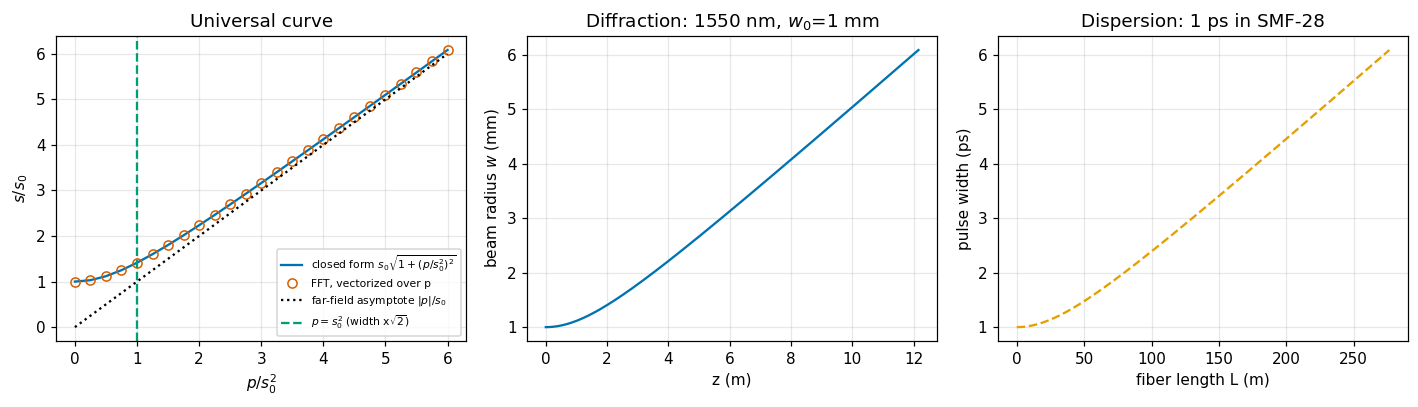

Figure 1. Left: the dimensionless width s/s0 against p/s0^2. The solid blue closed form passes through every open red circle (FFT, all 25 p values in one call). The dotted black line is the far-field asymptote |p|/s0, and the dashed green line marks p = s0^2, where the width has grown by sqrt(2). Middle: the same curve for a 1550 nm beam, radius 1 mm -> sqrt(2) mm at z_R = 2.03 m. Right: the same curve again (dashed orange) for a 1 ps pulse, which reaches sqrt(2) ps after L_D = 46.1 m of SMF-28. Same shape, different axis labels.
max relative error of measured width: 2.2e-16


In [6]:
ps = np.linspace(0, 6, 25)
U = dd.quadratic_phase_propagate(u0, d, ps)                 # shape (25, 4096): one FFT pass
s_meas = np.sqrt(2) * dd.rms_width(x, U)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(ps, dd.gaussian_width(1.0, ps), '-', color=OI['blue'], label='closed form $s_0\\sqrt{1+(p/s_0^2)^2}$')
ax[0].plot(ps, s_meas, 'o', mfc='none', color=OI['red'], label='FFT, vectorized over p')
ax[0].plot(ps, np.abs(ps), ':', color=OI['black'], label='far-field asymptote $|p|/s_0$')
ax[0].axvline(1, ls='--', color=OI['green'], label='$p=s_0^2$ (width x$\\sqrt{2}$)')
ax[0].set(xlabel='$p/s_0^2$', ylabel='$s/s_0$', title='Universal curve'); ax[0].legend(fontsize=7)
z = np.linspace(0, 6*zR, 200)
ax[1].plot(z, 1e3*np.sqrt(2)*dd.gaussian_width(s0_beam, dd.diffraction_p(z, lam)), '-', color=OI['blue'])
ax[1].set(xlabel='z (m)', ylabel='beam radius $w$ (mm)', title='Diffraction: 1550 nm, $w_0$=1 mm')
L = np.linspace(0, 6*LD, 200)
ax[2].plot(L, 1e12*dd.gaussian_width(T0, dd.dispersion_p(beta2, L)), '--', color=OI['orange'])
ax[2].set(xlabel='fiber length L (m)', ylabel='pulse width (ps)', title='Dispersion: 1 ps in SMF-28')
plt.tight_layout(); plt.show()
print('Figure 1. Left: the dimensionless width s/s0 against p/s0^2. The solid blue closed form passes through every '
      'open red circle (FFT, all 25 p values in one call). The dotted black line is the far-field asymptote |p|/s0, '
      'and the dashed green line marks p = s0^2, where the width has grown by sqrt(2). Middle: the same curve for a '
      f'1550 nm beam, radius 1 mm -> sqrt(2) mm at z_R = {zR:.2f} m. Right: the same curve again (dashed orange) for a '
      f'1 ps pulse, which reaches sqrt(2) ps after L_D = {LD:.1f} m of SMF-28. Same shape, different axis labels.')
print(f'max relative error of measured width: {np.max(np.abs(s_meas/dd.gaussian_width(1.0, ps)-1)):.1e}')

## 4. Figure 2: the far field is the Fourier transform (Fraunhofer ↔ time-stretch)

Input: two unequal, offset Gaussians. This field is asymmetric on purpose, so a sign error in $x=-p\nu$ would show up. The Fresnel number $N_F=\text{size}^2/|p|$ tells you which regime you're in.

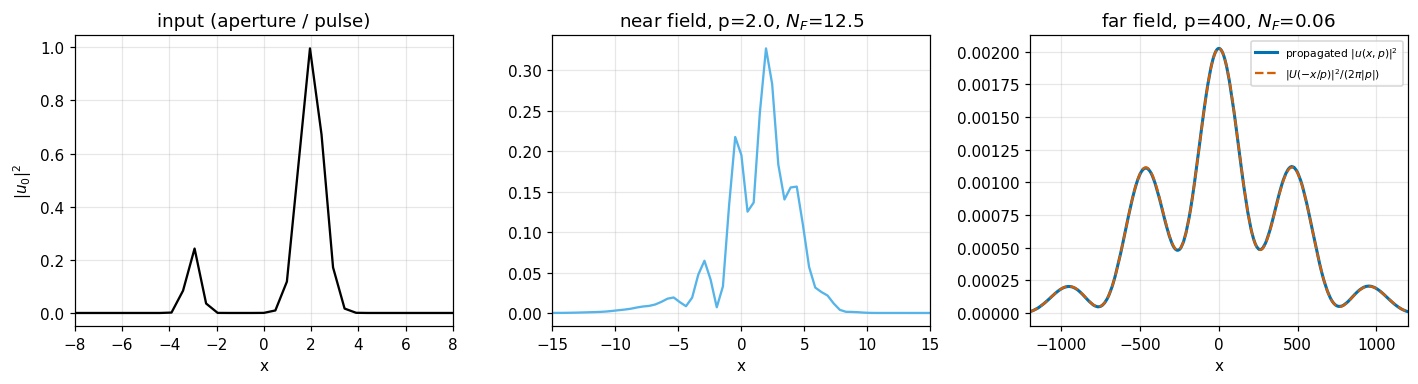

Figure 2. Left: the asymmetric input intensity (black), a tall peak at x=2 and a smaller one at x=-3. Middle: at p=2 (Fresnel number 12, near field) the two peaks have blurred and begin to interfere (sky blue). Right: at p=400 (Fresnel number 0.06, far field) the propagated intensity (solid blue) lies on the input power spectrum mapped through x = -p nu (dashed red): fringes from the two-peak interference, under a broad envelope set by the narrow peak. Peak-normalized max difference: 0.004. In optics this is Fraunhofer diffraction; in a fiber it is the dispersive Fourier transform that turns an oscilloscope into a single-shot spectrometer.


In [7]:
x2 = (np.arange(8192) - 4096) * (4000/8192); d2 = x2[1]-x2[0]
v0 = dd.gaussian_field(x2-2, 0.7) + 0.5*dd.gaussian_field(x2+3, 0.4)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(x2, np.abs(v0)**2, '-', color=OI['black']); ax[0].set(xlim=(-8, 8), xlabel='x', ylabel='$|u_0|^2$', title='input (aperture / pulse)')
p_near = 2.0
ax[1].plot(x2, np.abs(dd.quadratic_phase_propagate(v0, d2, p_near))**2, '-', color=OI['sky'])
ax[1].set(xlim=(-15, 15), xlabel='x', title=f'near field, p={p_near}, $N_F$={dd.fresnel_number(5, p_near):.1f}')
p_far = 400.0
I_far = np.abs(dd.quadratic_phase_propagate(v0, d2, p_far))**2
ax[2].plot(x2, I_far, '-', color=OI['blue'], lw=2, label='propagated $|u(x,p)|^2$')
ax[2].plot(x2, dd.far_field_prediction(v0, d2, x2, p_far), '--', color=OI['red'], label='$|U(-x/p)|^2/(2\\pi|p|)$')
ax[2].set(xlim=(-1200, 1200), xlabel='x', title=f'far field, p={p_far:.0f}, $N_F$={dd.fresnel_number(5, p_far):.2f}'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
err = np.max(np.abs(I_far - dd.far_field_prediction(v0, d2, x2, p_far))) / I_far.max()
print('Figure 2. Left: the asymmetric input intensity (black), a tall peak at x=2 and a smaller one at x=-3. Middle: at '
      'p=2 (Fresnel number 12, near field) the two peaks have blurred and begin to interfere (sky blue). Right: at '
      'p=400 (Fresnel number 0.06, far field) the propagated intensity (solid blue) lies on the input power spectrum '
      'mapped through x = -p nu (dashed red): fringes from the two-peak interference, under a broad envelope set by the narrow '
      f'peak. Peak-normalized max difference: {err:.3f}. In optics this is Fraunhofer diffraction; in a fiber it is the '
      'dispersive Fourier transform that turns an oscilloscope into a single-shot spectrometer.')

## 5. Figure 3: vectorization (loop vs broadcasting vs FFT)

The same propagation done three ways:

1. **Python loops:** the Fresnel convolution $u(x_i)=\sum_j K(x_i-x_j)\,u_0(x_j)\,\Delta x$ with $K(x)=e^{-ix^2/2p}/\sqrt{-2\pi i p}$. That's $O(n^2)$ *interpreted* steps.
2. **Broadcasting:** build the whole $n\times n$ kernel matrix with `x[:, None] - x[None, :]`, then one matrix-vector product. Still $O(n^2)$, but the loop runs in compiled code.
3. **FFT:** multiply by $H(\nu)$ in the frequency domain, $O(n\log n)$. A 2D batch over many $p$ is one more broadcast.

n=256: max|loop - broadcast| = 8.9e-16,  max|broadcast - exact| = 5.0e-08


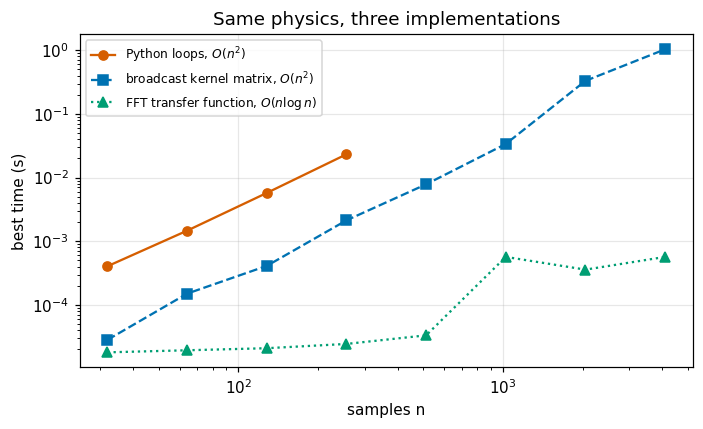

Figure 3. Log-log run time against the number of samples. Red circles, solid: pure-Python double loop. Blue squares, dashed: the broadcast kernel matrix. Green triangles, dotted: the FFT method. Both direct methods have slope about 2 (O(n^2)); the FFT line is nearly flat at these sizes.
At n=256: loop 23 ms, broadcast 2.13 ms (11x faster), FFT 24 us (954x faster than the loop).


2000 values of p on n=4096: one broadcast call 0.65 s vs loop over p 0.83 s


In [8]:
def timeit(f, reps=3):
    best = np.inf
    for _ in range(reps):
        t = time.perf_counter(); f(); best = min(best, time.perf_counter() - t)
    return best

p = 0.3
sizes_loop, sizes = [32, 64, 128, 256], [32, 64, 128, 256, 512, 1024, 2048, 4096]
t_loop, t_vec, t_fft = [], [], []
for n in sizes:
    xs = (np.arange(n) - n//2) * (25.6/n) if n <= 256 else (np.arange(n) - n//2) * 0.1
    us = dd.gaussian_field(xs, 1.0)
    if n in sizes_loop:
        t_loop.append(timeit(lambda: dd.fresnel_direct_loop(us, xs, p), reps=1))
    t_vec.append(timeit(lambda: dd.fresnel_direct_vectorized(us, xs, p)))
    t_fft.append(timeit(lambda: dd.quadratic_phase_propagate(us, xs[1]-xs[0], p)))

n = 256; xs = (np.arange(n) - n//2) * 0.1; us = dd.gaussian_field(xs, 1.0)
a, b, c = dd.fresnel_direct_loop(us, xs, p), dd.fresnel_direct_vectorized(us, xs, p), dd.gaussian_exact(xs, 1.0, p)
print(f'n=256: max|loop - broadcast| = {np.max(np.abs(a-b)):.1e},  max|broadcast - exact| = {np.max(np.abs(b-c)):.1e}')

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(sizes_loop, t_loop, 'o-', color=OI['red'], label='Python loops, $O(n^2)$')
ax.loglog(sizes, t_vec, 's--', color=OI['blue'], label='broadcast kernel matrix, $O(n^2)$')
ax.loglog(sizes, t_fft, '^:', color=OI['green'], label='FFT transfer function, $O(n\\log n)$')
ax.set(xlabel='samples n', ylabel='best time (s)', title='Same physics, three implementations'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
i256 = sizes.index(256)
print('Figure 3. Log-log run time against the number of samples. Red circles, solid: pure-Python double loop. Blue '
      'squares, dashed: the broadcast kernel matrix. Green triangles, dotted: the FFT method. Both direct methods have '
      'slope about 2 (O(n^2)); the FFT line is nearly flat at these sizes.')
print(f'At n=256: loop {t_loop[-1]*1e3:.0f} ms, broadcast {t_vec[i256]*1e3:.2f} ms ({t_loop[-1]/t_vec[i256]:.0f}x faster), '
      f'FFT {t_fft[i256]*1e6:.0f} us ({t_loop[-1]/t_fft[i256]:.0f}x faster than the loop).')

# batch: 2000 distances in one broadcast call vs a Python loop over p
pb = np.linspace(0.1, 50, 2000)
t_batch = timeit(lambda: dd.quadratic_phase_propagate(u0, d, pb), reps=1)
t_each = timeit(lambda: [dd.quadratic_phase_propagate(u0, d, q) for q in pb], reps=1)
print(f'2000 values of p on n=4096: one broadcast call {t_batch:.2f} s vs loop over p {t_each:.2f} s')

## 6. Figure 4: Talbot carpet (spatial grating = pulse train)

A periodic field (slits of period $\Lambda$, or pulses of period $T$) is propagated to 600 values of $p$ at once. The result is a 2D array whose rows are the field at each distance. It revives at $p_T=\Lambda^2/\pi$ and shows a half-period-shifted copy at $p_T/2$.

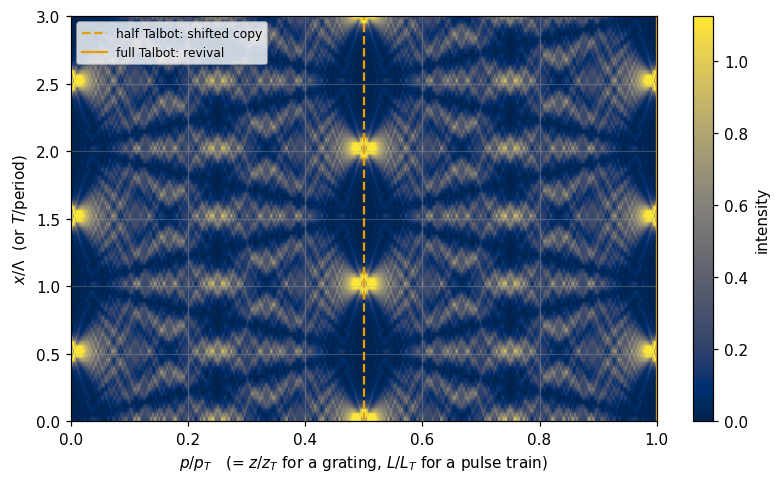

Figure 4. Talbot carpet: horizontal axis is propagation in units of the Talbot length, vertical axis is three periods of the field; brightness is intensity (cividis map, readable in grayscale). Bright bars at the left edge are the input slits; the pattern breaks into finer fractional images, reappears shifted by half a period at the dashed orange line, and returns to the original at the solid orange line.
max|u(p_T) - u0| = 2.3e-14;  max|u(p_T/2) - u0 shifted by Lambda/2| = 1.1e-14
Physical: 100 um grating at 1550 nm -> z_T = 12.9 mm; 10 GHz pulse train in SMF-28 -> L_T = 147 km.


In [9]:
n, period = 1024, 8.0
dT = 32*period/n
xt = np.arange(n)*dT
g0 = (np.abs((xt % period) - period/2) < 1.0).astype(complex)
pT = dd.talbot_p(period)
pc = np.linspace(0, pT, 600)
carpet = np.abs(dd.quadratic_phase_propagate(g0, dT, pc))**2     # (600, 1024) in one call
m = xt < 3*period
fig, ax = plt.subplots(figsize=(7.5, 4.5))
im = ax.imshow(carpet[:, m].T, aspect='auto', origin='lower', cmap='cividis', vmax=np.percentile(carpet, 99.5),
               extent=[0, 1, 0, 3])
for f, ls, lab in [(0.5, '--', 'half Talbot: shifted copy'), (1.0, '-', 'full Talbot: revival')]:
    ax.axvline(f, color=OI['orange'], ls=ls, lw=1.5, label=lab)
ax.set(xlabel='$p/p_T$   (= $z/z_T$ for a grating, $L/L_T$ for a pulse train)', ylabel='$x/\\Lambda$  (or $T$/period)')
ax.legend(loc='upper left', fontsize=8); plt.colorbar(im, label='intensity'); plt.tight_layout(); plt.show()
rev = np.max(np.abs(dd.quadratic_phase_propagate(g0, dT, pT) - g0))
half = np.max(np.abs(dd.quadratic_phase_propagate(g0, dT, pT/2) - np.roll(g0, int(period/2/dT))))
print('Figure 4. Talbot carpet: horizontal axis is propagation in units of the Talbot length, vertical axis is three '
      'periods of the field; brightness is intensity (cividis map, readable in grayscale). Bright bars at the left edge '
      'are the input slits; the pattern breaks into finer fractional images, reappears shifted by half a period at the '
      'dashed orange line, and returns to the original at the solid orange line.')
print(f'max|u(p_T) - u0| = {rev:.1e};  max|u(p_T/2) - u0 shifted by Lambda/2| = {half:.1e}')
print(f'Physical: 100 um grating at 1550 nm -> z_T = {dd.talbot_length_diffraction(100e-6, lam)*1e3:.1f} mm; '
      f'10 GHz pulse train in SMF-28 -> L_T = {dd.talbot_length_dispersion(100e-12, beta2)/1e3:.0f} km.')

## 7. Lean 4 proofs

These are the exact integer facts behind §1 and §6, checked by the Lean kernel. It's core Lean 4 only (no Mathlib), so the statements are about natural numbers and integers:

* `sq_parity`: $m^2 \equiv m \pmod 2$, which is why the half-Talbot image is a **shifted copy**.
* `talbot_whole_turns`: $2m^2$ is even, so every harmonic makes whole turns at $p_T$.
* `chirp_periodic`: $(n+N)^2\equiv n^2 \pmod N$, so a discrete quadratic phase on an $N$-point DFT grid is periodic (the reason the FFT method is consistent).
* `width_never_shrinks`, `one_length_doubles`: $s^2s_0^2=s_0^4+p^2\ge s_0^4$; at $p=s_0^2$ the squared width doubles.
* `temporal_talbot_km`: the 10 GHz SMF-28 Talbot length, floored to about 147 km.

In [10]:
LEAN_SRC = r'''
-- generated by diffraction_dispersion.ipynb (core Lean 4, no Mathlib)

-- Half-Talbot shift: harmonic m picks up phase pi*m^2 = pi*m (mod 2 pi) because m^2 and m have equal parity
theorem sq_parity (m : Nat) : m * m % 2 = m % 2 := by
  rcases Nat.mod_two_eq_zero_or_one m with h | h <;> simp [Nat.mul_mod, h]

-- Full Talbot revival: phase 2 pi m^2 is a whole number of turns for every harmonic m
theorem talbot_whole_turns (m : Nat) : (2 * (m * m)) % 2 = 0 := Nat.mul_mod_right 2 (m * m)

-- Discrete chirp: the DFT-grid quadratic phase n^2 mod N repeats with period N
theorem chirp_periodic (n N : Nat) : (n + N) * (n + N) % N = n * n % N := by
  have h : (n + N) * (n + N) = n * n + N * (2 * n + N) := by
    simp only [Nat.add_mul, Nat.mul_add, Nat.two_mul, Nat.mul_comm N n]; omega
  rw [h, Nat.add_mul_mod_self_left]

-- Gaussian width s^2 s0^2 = s0^4 + p^2 never shrinks below the waist (s0^4)
theorem width_never_shrinks (s0 p : Nat) : s0 ^ 4 ≤ s0 ^ 4 + p ^ 2 := Nat.le_add_right _ _

-- At one Rayleigh / dispersion length (p = s0^2) the squared width doubles
theorem one_length_doubles (s0 : Nat) : s0 ^ 4 + (s0 ^ 2) ^ 2 = 2 * s0 ^ 4 := by
  rw [← Nat.pow_mul]; show s0 ^ 4 + s0 ^ 4 = 2 * s0 ^ 4; omega

-- Duality is symmetric: mapping z/k -> -beta2 L twice returns the original (negation is an involution)
theorem duality_involution (p : Int) : -(-p) = p := Int.neg_neg p

-- Numbers: 10 GHz pulse train (T = 100 ps), SMF beta2 = 21.7 ps^2/km:
-- L_T = T^2/(pi |beta2|) ~ 10000/(3.1416*21.7) km; integer check 10000 / 68 = 147 km (floor)
theorem temporal_talbot_km : 10000 / 68 = 147 := by decide
'''

lean_file = pathlib.Path.cwd() / 'diffraction_dispersion.lean'
lean_file.write_text(LEAN_SRC.strip() + '\n', encoding='utf-8')
print(LEAN_SRC.strip())
r = subprocess.run(['lean', '+leanprover/lean4:v4.34.0-rc2', str(lean_file)], capture_output=True, text=True)
print(f'\n{lean_file.name}: exit code {r.returncode};', LEAN_SRC.count('theorem '), 'theorems')
print((r.stdout + r.stderr).strip() or 'no errors: every theorem verified by the Lean kernel')

-- generated by diffraction_dispersion.ipynb (core Lean 4, no Mathlib)

-- Half-Talbot shift: harmonic m picks up phase pi*m^2 = pi*m (mod 2 pi) because m^2 and m have equal parity
theorem sq_parity (m : Nat) : m * m % 2 = m % 2 := by
  rcases Nat.mod_two_eq_zero_or_one m with h | h <;> simp [Nat.mul_mod, h]

-- Full Talbot revival: phase 2 pi m^2 is a whole number of turns for every harmonic m
theorem talbot_whole_turns (m : Nat) : (2 * (m * m)) % 2 = 0 := Nat.mul_mod_right 2 (m * m)

-- Discrete chirp: the DFT-grid quadratic phase n^2 mod N repeats with period N
theorem chirp_periodic (n N : Nat) : (n + N) * (n + N) % N = n * n % N := by
  have h : (n + N) * (n + N) = n * n + N * (2 * n + N) := by
    simp only [Nat.add_mul, Nat.mul_add, Nat.two_mul, Nat.mul_comm N n]; omega
  rw [h, Nat.add_mul_mod_self_left]

-- Gaussian width s^2 s0^2 = s0^4 + p^2 never shrinks below the waist (s0^4)
theorem width_never_shrinks (s0 p : Nat) : s0 ^ 4 ≤ s0 ^ 4 + p ^ 2 := Nat.le_add_right _ _

-- At 


diffraction_dispersion.lean: exit code 0; 7 theorems
no errors: every theorem verified by the Lean kernel


## 8. Jalali lab connection

* **Photonic time-stretch** [2], [3]: a pulse is stretched by a large $|\beta_2 L|$ so a fast signal slows down enough to digitize. This is §4's far field, with $N_F\ll1$.
* **STEAM camera** [4]: a spatial image is mapped onto the spectrum by a diffraction grating (space→frequency), then onto time by dispersion (frequency→time, §4). It uses both halves of this notebook in one instrument.
* **Phase Stretch Transform (PST)** [6]: applies a dispersion-like *nonlinear* spectral phase to a digital image to pick out edges; a generalization of $H(\nu)$ from §1.
* **This repo's GS phase retrieval:** measuring $|u(x,p_1)|^2$ and $|u(x,p_2)|^2$ at two values of $p$ (two dispersions $D$) provides the phase diversity that the Gerchberg-Saxton loop needs. The forward model is `quadratic_phase_propagate`.
* **Optical rogue waves** [5]: add the Kerr term $\gamma|A|^2A$ to the §1 equation and it becomes the nonlinear Schrödinger equation.
* **Knight Ch. 40:** set $p=-\hbar t/m$; §3 is free-particle wave-packet spreading, and §1's complex width is the textbook Gaussian packet.

## References

[1] B. H. Kolner, "Space-time duality and the theory of temporal imaging," *IEEE J. Quantum Electron.*, vol. 30, no. 8, pp. 1951–1963, 1994.
[2] K. Goda and B. Jalali, "Dispersive Fourier transformation for fast continuous single-shot measurements," *Nat. Photonics*, vol. 7, pp. 102–112, 2013.
[3] F. Coppinger, A. S. Bhushan, and B. Jalali, "Photonic time stretch and its application to analog-to-digital conversion," *IEEE Trans. Microw. Theory Tech.*, vol. 46, no. 7, pp. 1309–1314, 1998.
[4] K. Goda, K. K. Tsia, and B. Jalali, "Serial time-encoded amplified imaging for real-time observation of fast dynamic phenomena," *Nature*, vol. 458, pp. 1145–1149, 2009.
[5] D. R. Solli, C. Ropers, P. Koonath, and B. Jalali, "Optical rogue waves," *Nature*, vol. 450, pp. 1054–1057, 2007.
[6] M. H. Asghari and B. Jalali, "Edge detection in digital images using dispersive phase stretch transform," *Int. J. Biomed. Imaging*, vol. 2015, Art. no. 687819, 2015.
[7] J. W. Goodman, *Introduction to Fourier Optics*, 3rd ed. Englewood, CO, USA: Roberts & Co., 2005.

**Limitations.** References were written from memory; check volume and page numbers before citing. Everything here is second-order only: no $\beta_3$, no aperture apodization beyond the Gaussian. The FFT method is periodic, so fields must stay inside the window. The Lean proofs cover integer facts only; real-analysis statements (Gaussian integrals, stationary phase) would need Mathlib.